# Business Problem
<p>A global e-commerce company operating across multiple regions manages end-to-end order fulfillment, including shipping and delivery, for products like sporting goods. The company is facing inconsistent delivery performance, where actual shipping times often deviate from scheduled timelines, leading to late deliveries and unpredictable order profitability.</p>

## Desired Outcome:
<p> The goal is to analyze delivery operations, identify bottlenecks, and build a predictive system to reduce delays, optimize shipping decisions, and improve overall profitability and efficiency.</p>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# extra visual presentation
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
df = pd.read_csv(r"C:\data analytics\PORTFOLIO_PROJECT\Supply Chain Analysis\DataCoSupplyChainDataset.csv", encoding='unicode_escape')

# Display all columns
pd.set_option('display.max_columns', None)

df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [3]:
# show all columns name
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

## Exploratory data analysis

In [4]:
# overview
print('Rows & columns=', df.shape)

print('------------ columns ------')
print(df.columns.tolist())

print('------------ duplicates ------')
print(df.duplicated().sum())

print('------------- missing values ------')
print(df.isnull().sum().sort_values(ascending=False))


Rows & columns= (180519, 53)
------------ columns ------
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'P

In [5]:
# data cleaning 
columns_to_all_drop = ['Product Description',
                  'Product Image',
                   'Customer Email', 
                   'Customer Fname', 
                   'Customer Id',
                   'Customer Lname', 
                   'Customer Password',
                   'Customer Street', 
                   'Customer Zipcode',
                   'Latitude', 'Longitude',
                   'Order Zipcode',
                   'Order Id', 
                   'Order Item Cardprod Id', 
                   'Order Item Discount', 
                   'Order Item Discount Rate', 
                   'Order Item Id', 
                   'Order Item Product Price',
                   'Order Item Quantity', 
                   'Order Item Total',
                   'Category Id','Department Id',
                   'Order Customer Id','Customer Id',
                   'Product Card Id',
                   'Product Category Id',
                   'Benefit per order',   # identical to order profilt per order
                   'Product Status',      # have only one value
                   'Customer City','Order City',
                   'Order Country','Order State',
                   'Customer State',
                   'Market'
                  ]

# dropping columns that are either fully missing
df = df.drop(columns=columns_to_all_drop)
df

,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Order Region,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,1/31/2018 22:56,0.29,327.750000,91.250000,Southeast Asia,COMPLETE,Smart watch,327.750000,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,1/13/2018 12:27,-0.80,327.750000,-249.089996,South Asia,PENDING,Smart watch,327.750000,1/18/2018 12:27,Standard Class
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,1/13/2018 12:06,-0.80,327.750000,-247.779999,South Asia,CLOSED,Smart watch,327.750000,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,1/13/2018 11:45,0.08,327.750000,22.860001,Oceania,COMPLETE,Smart watch,327.750000,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,1/13/2018 11:24,0.45,327.750000,134.210007,Oceania,PENDING_PAYMENT,Smart watch,327.750000,1/15/2018 11:24,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,399.980011,Shipping on time,0,Fishing,EE. UU.,Home Office,Fan Shop,1/16/2016 3:40,0.10,399.980011,40.000000,Eastern Asia,CLOSED,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,395.980011,Late delivery,1,Fishing,EE. UU.,Corporate,Fan Shop,1/16/2016 1:34,-1.55,399.980011,-613.770019,Eastern Asia,COMPLETE,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,391.980011,Late delivery,1,Fishing,EE. UU.,Corporate,Fan Shop,1/15/2016 21:00,0.36,399.980011,141.110001,Oceania,PENDING,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,387.980011,Advance shipping,0,Fishing,Puerto Rico,Consumer,Fan Shop,1/15/2016 20:18,0.48,399.980011,186.229996,Oceania,PENDING_PAYMENT,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,1/18/2016 20:18,Standard Class


In [6]:
# removing canceled orders sice they not relevent for delivery time analysis and may have different patterns than completed orders
df = df[df['Delivery Status'] != 'Shipping canceled']
df

# standard date conversion
for i in ['order date (DateOrders)', 'shipping date (DateOrders)']:
    df[i] = pd.to_datetime(df[i], errors='coerce', dayfirst=False)

# after data cleaning, lets check the overview again to see how the dataset has changed
print('rows, cols:', df.shape)
print('---- Missing values top-5 ---')
print(df.isna().sum().sort_values(ascending=False).head())

rows, cols: (172765, 20)
---- Missing values top-5 ---
Type                          0
Days for shipping (real)      0
shipping date (DateOrders)    0
Product Price                 0
Product Name                  0
dtype: int64


In [7]:
# value count for categorical columns with low cardinality

for col in df.columns:
    if df[col].nunique() < 10:
        print(f'\n--- {col} value counts:')
        print(df[col].value_counts())


--- Type value counts:
Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

--- Days for shipping (real) value counts:
Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

--- Days for shipment (scheduled) value counts:
Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

--- Delivery Status value counts:
Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

--- Late_delivery_risk value counts:
Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

--- Customer Country value counts:
Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64

--- Customer Segment value counts:
Customer Segment
Consumer       89420
Corporate      52528
Home Office    30817
Name: count, dtype: int64

--- Order Status value

In [8]:
# calculating order processing time and delay
df['Order processing time'] = (df['shipping date (DateOrders)'] - df['order date (DateOrders)']).dt.days

df['Delay'] = df['Order processing time'] - df['Days for shipment (scheduled)']

df['IS_delayed'] = df['Delay'] > 0

df['Order_month'] = df['order date (DateOrders)'].dt.month

df['Order_day'] = df['order date (DateOrders)'].dt.day_name()

df["Order_hour"] = df['order date (DateOrders)'].dt.hour

df.describe()

,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Late_delivery_risk,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Product Price,shipping date (DateOrders),Order processing time,Delay,Order_month,Order_hour
count,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000
mean,3.498596,2.933100,183.165948,0.572900,2016-06-12 15:25:39.457991936,0.120801,203.828493,22.032360,141.278595,2016-06-16 03:25:14.452927488,3.472816,0.539716,6.235511,11.482604
min,0.000000,0.000000,7.490000,0.000000,2015-01-01 00:00:00,-2.750000,9.990000,-4274.979980,9.990000,2015-01-03 00:00:00,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,104.379997,0.000000,2015-09-21 18:01:00,0.080000,119.980003,7.030000,50.000000,2015-09-25 08:59:00,2.000000,0.000000,3.000000,5.000000
50%,3.000000,4.000000,163.990005,1.000000,2016-06-11 08:11:00,0.270000,199.919998,31.520000,59.990002,2016-06-15 03:38:00,3.000000,1.000000,6.000000,11.000000
75%,5.000000,4.000000,247.399994,1.000000,2017-02-28 21:08:00,0.360000,299.950012,64.800003,199.990005,2017-03-04 08:00:00,5.000000,1.000000,9.000000,17.000000
max,6.000000,4.000000,1939.989990,1.000000,2018-01-31 23:38:00,0.500000,1999.989990,911.799988,1999.989990,2018-02-06 22:14:00,6.000000,4.000000,12.000000,23.000000
std,1.623446,1.373405,120.141871,0.494659,NaN,0.466610,132.392520,104.355313,139.862956,NaN,1.670187,1.494150,3.405593,6.927276


In [9]:
df['IS_delayed'].value_counts()

IS_delayed
True     94523
False    78242
Name: count, dtype: int64

In [10]:
# Profitability flag based on order profit per order
# df.columns

df['Profitability_flag'] = np.where(df['Order Profit Per Order'] > 0,'Profit', np.where(df['Order Profit Per Order'] < 0,'Loss', 'Break-even'))
#                       condition(order > 0 = profit - write) ,                 condition(order < 0 = Loss - write)            , else(break-even)
# df['Profitability_flag']
df['Profitability_flag'].value_counts()

Profitability_flag
Profit        139354
Loss           32295
Break-even      1116
Name: count, dtype: int64

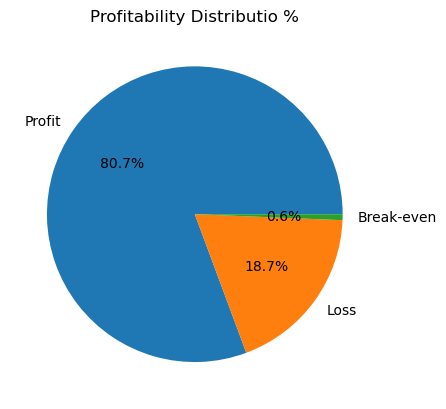

In [11]:
# visualization of profitability distribution

# calculate percentage
profit_counts = df['Profitability_flag'].value_counts(normalize=True) * 100

#                   chart      label               
profit_counts.plot(kind='pie', autopct='%1.1f%%')
plt.ylabel('')
plt.title('Profitability Distributio %')
plt.show()

# Dashboard

In [12]:
# KPIs

def formate_func(value):
    if value >= 1e6:
        return f'{value/1e6:.1f} M $'
    elif value >= 1e3:
        return f'{value/1e3:.1f} K $'
    else:
        return f"{value:.0f} $"

delayed_df = df[df['Delay'] > 0] 

metrics = {}

metrics['Total orders'] = len(df)
metrics['Late Deliveries'] = len(delayed_df)
metrics['90% delay (Days)'] = delayed_df['Delay'].quantile(0.90)
metrics['On time delivery %'] = (1-float(metrics['Late Deliveries']) / metrics['Total orders']) * 100
metrics['Late delivery %'] = float(metrics['Late Deliveries']) / metrics['Total orders'] * 100
metrics['Total Profit'] = formate_func(df.loc[df['Order Profit Per Order'] > 0, 'Order Profit Per Order'].sum())
metrics['Total loss due to delay'] = formate_func(df.loc[df['Delay'] > 0, 'Order Profit Per Order'].sum())


print("\n------------- Business KPIs------------------\n")
for k,v in metrics.items():
    if isinstance(v, float):
        print(f'{k}: {v:2f}')
    else:
        print(f'{k}: {v}')


------------- Business KPIs------------------

Total orders: 172765
Late Deliveries: 94523
90% delay (Days): 3.000000
On time delivery %: 45.288108
Late delivery %: 54.711892
Total Profit: 7.5 M $
Total loss due to delay: 2.1 M $


<h2> Profitability vs Delivery Time Analysis

In [13]:
profit_metrics = (
    df.groupby("Delay")['Order Profit Per Order'].agg(mean_profit = 'mean', total_profit='sum', order_count='count')
).reset_index()

profit_metrics

,Delay,mean_profit,total_profit,order_count
0,-2,23.360134,4.875961e+05,20873
1,-1,21.604769,4.476292e+05,20719
2,0,22.249118,8.154302e+05,36650
3,1,22.333227,1.194895e+06,53503
4,2,21.128491,5.821110e+05,27551
5,3,20.031412,1.356527e+05,6772
6,4,21.368783,1.431067e+05,6697


In [14]:
delay_distribution = (df['Delay'].value_counts(normalize=True).sort_index() * 100).reset_index()
delay_distribution

,Delay,proportion
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364



 Profit Metrics by Delay Day


,Delay_Days,Percentage
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364


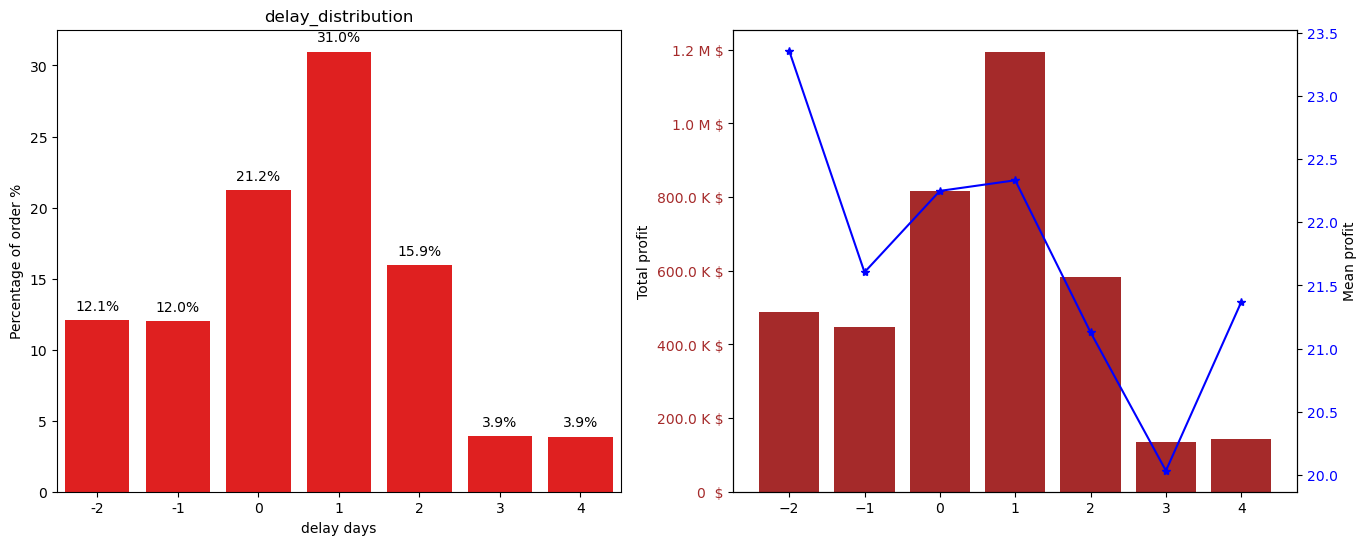

In [15]:
# visualization

delay_distribution.columns = ['Delay_Days','Percentage']
print('\n Profit Metrics by Delay Day')
display(delay_distribution)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))

# first subplot : Delay Distribution
sns.barplot(x='Delay_Days', y='Percentage', data=delay_distribution, color='red', ax=ax1)
ax1.set_title('delay_distribution')
ax1.set_xlabel('delay days')
ax1.set_ylabel('Percentage of order %')

# percentage text on bar
for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height + 0.5, f"{height:.1f}%", ha='center', va='bottom')

# second subplot : profit analysis by delay days
ax2.set_ylabel('Total profit')
ax2.bar(profit_metrics['Delay'], profit_metrics['total_profit'], color='Brown', label='total profit')
ax2.tick_params(axis='y', labelcolor='Brown')

ax3=ax2.twinx()

ax3.set_label('Delay Days')
ax3.set_ylabel('Mean profit')
ax3.plot(profit_metrics['Delay'], profit_metrics['mean_profit'], marker='*', label='Mean profit', color='Blue')
ax3.tick_params(axis='y', labelcolor='Blue')

# format total profit axis to k $, M $
def format_func(value, tick_number):
    if value >= 1e6:
        return f'{value/1e6:.1f} M $'
    elif value >= 1e3:
        return f'{value/1e3:.1f} K $'
    else:
        return f'{value:.0f}  $'
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(format_func))

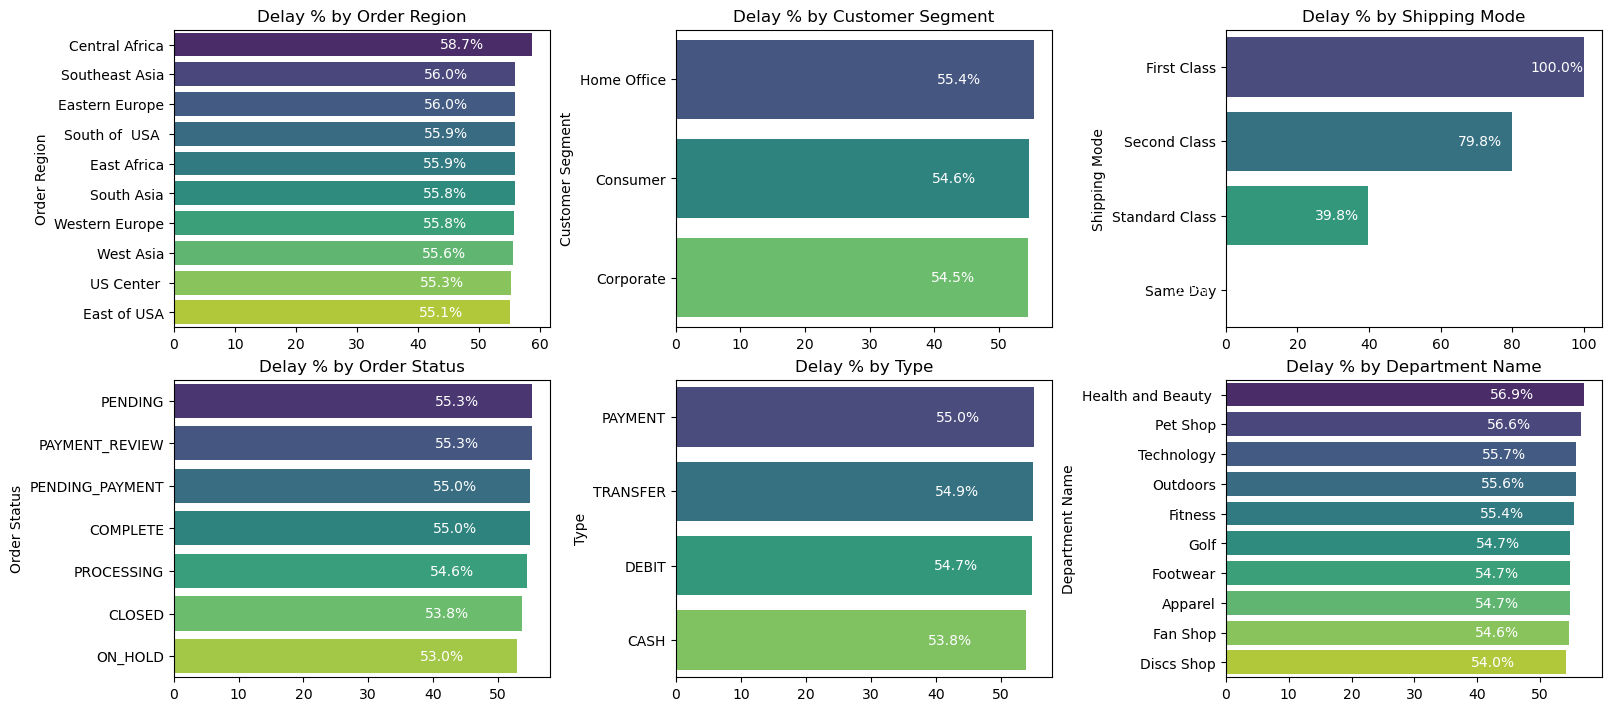

In [16]:
# Bottelneck detection

def compute_delay_pct_category(category):
    cat_df = df.groupby(category).agg(
        total_orders = ('Delay', 'count'),
        late_orders = ('IS_delayed', 'sum')
    ).reset_index()
    cat_df['delay_pct'] = cat_df['late_orders'] / cat_df['total_orders'] * 100
    cat_df = cat_df.sort_values('delay_pct', ascending=False).head(10)
    return cat_df

categories = ['Order Region', 'Customer Segment','Shipping Mode','Order Status','Type','Department Name']

fig, axes = plt.subplots(2,3, figsize=(16,7), constrained_layout=True)
axes = axes.flatten()

for ax, category in zip(axes, categories):
    cat_df = compute_delay_pct_category(category)
    sns.barplot(data=cat_df, x='delay_pct', y=category, ax=ax, palette='viridis')

    ax.set_title(f"Delay % by {category}")
    ax.set_xlabel('')
    ax.set_ylabel(category)
    for i, row in cat_df.reset_index().iterrows():
        ax.text(row['delay_pct'] - 15, i, f"{row['delay_pct']:.1f}%", va='center', fontsize=10, color='white')
plt.show()
        

<h2> Root cause analysis

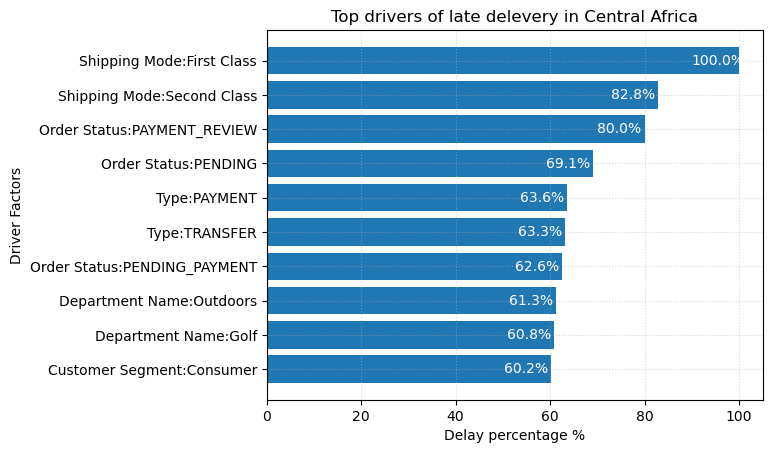

In [17]:
# top drivers of late delivery by region
def top_drivers_for_region(region):
    df_region = df[df['Order Region'] == region].copy()

    drivers = ['Shipping Mode','Customer Segment','Department Name','Type','Order Status']

    all_factors = []
    for factor in drivers:
        temp = (df_region.groupby(factor).agg(total_orders=('Delay','count'),
                                             late_orders = ('IS_delayed','sum'),
                                             avg_delay = ('Delay','mean')
                                             ).reset_index())
        temp['delay_pct'] = temp['late_orders'] / temp['total_orders'] * 100
        temp['Driver'] = factor
        temp['Factor_level'] = factor + ':' + temp[factor].astype(str)

        all_factors.append(temp[['Driver', 'Factor_level','delay_pct','avg_delay', 'total_orders']])

    # combine all drivers
    final_df = pd.concat(all_factors)

    # top 10 drivers
    top_factors = final_df.sort_values('delay_pct', ascending=False).head(10)
    
    plt.figure()
    bars = plt.barh(top_factors['Factor_level'], top_factors['delay_pct'])
    plt.xlabel('Delay percentage %')
    plt.ylabel('Driver Factors')
    plt.title(f'Top drivers of late delevery in {region}')
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.gca().invert_yaxis()
    for bar in bars:
        width = bar.get_width()
        plt.text(width - 10, bar.get_y() + bar.get_height()/2,
                f'{width:.1f}%',
                va='center', fontsize=10, color='white')
    plt.show()

top_drivers_for_region('Central Africa')

<h2> Time Based Analysis

In [18]:
# Delay % by Month of week, hour

delay_by_month = df.groupby('Order_month')['IS_delayed'].mean().reset_index()
delay_by_month['delay_pct'] = delay_by_month['IS_delayed'] * 100

delay_by_day = df.groupby('Order_day')['IS_delayed'].mean().reset_index()
delay_by_day['delay_pct'] = delay_by_day['IS_delayed'] * 100

delay_by_hour = df.groupby('Order_hour')['IS_delayed'].mean().reset_index()
delay_by_hour['delay_pct'] = delay_by_hour['IS_delayed'] * 100


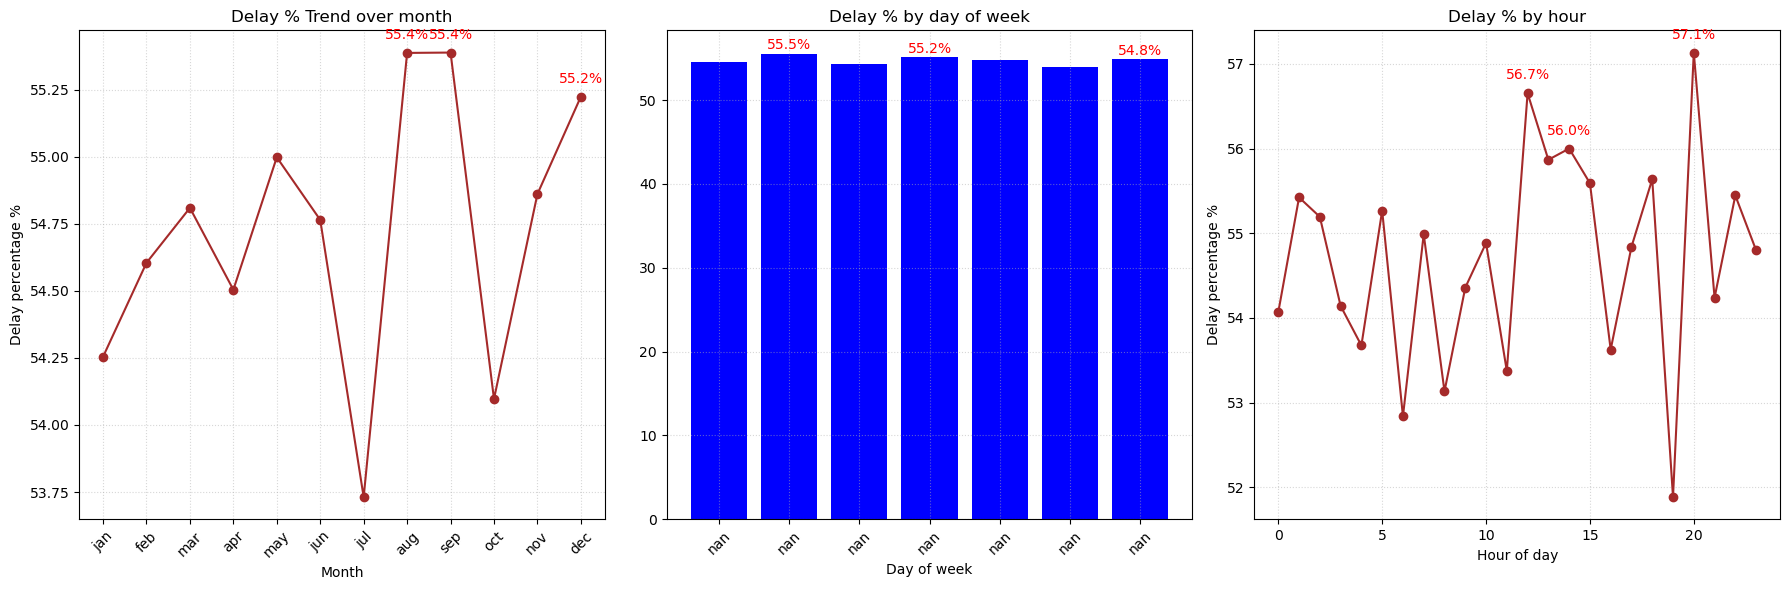

In [23]:
# visualization
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# Subplot 1: Delay % Trends over Month
ax1.plot(delay_by_month['Order_month'], delay_by_month['delay_pct'], marker='o', color='Brown')
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'], rotation=45)
ax1.set_xlabel("Month")
ax1.set_ylabel("Delay percentage %")
ax1.set_title("Delay % Trend over month")
ax1.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest months
top3_month = delay_by_month.nlargest(3, 'delay_pct')
for _, row in top3_month.iterrows():
    ax1.annotate(f"{row['delay_pct']:.1f}%", (row['Order_month'], row['delay_pct']), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=10, color="Red")

# Subplot 2: Delay % by Day of Week
day_order = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']
delay_by_day['Order_day'] = pd.Categorical(delay_by_day['Order_day'], categories=day_order, ordered=True)
delay_by_day = delay_by_day.sort_values('Order_day').reset_index(drop=True)

# FIXED HERE: Use numeric range for bar alignment, then label them
ax2.bar(range(len(delay_by_day)), delay_by_day['delay_pct'], color='Blue')
ax2.set_xticks(range(len(delay_by_day)))
ax2.set_xticklabels(delay_by_day['Order_day'], rotation=45)
ax2.set_xlabel('Day of week')
ax2.set_title('Delay % by day of week')
ax2.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest days
top3_days = delay_by_day.nlargest(3, 'delay_pct')
for idx, row in top3_days.iterrows():
    height = row['delay_pct']
    # FIXED HERE: Used the numeric index (idx) for exact coordinate matching
    ax2.text(idx, height + 0.5, f'{height:.1f}%', ha='center', fontsize=10, color="Red") 

# Subplot 3: Delay % by Hour of Day
ax3.plot(delay_by_hour['Order_hour'], delay_by_hour['delay_pct'], marker='o', color='Brown')
ax3.set_xlabel('Hour of day')
ax3.set_ylabel('Delay percentage %')
ax3.set_title('Delay % by hour')
ax3.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest hours
top3_hour = delay_by_hour.nlargest(3, 'delay_pct')
for _, row in top3_hour.iterrows():
    ax3.annotate(f"{row['delay_pct']:.1f}%", (row['Order_hour'], row['delay_pct']), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=10, color="Red")

plt.tight_layout()
plt.show()

<h2> Machine Learning Model

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE

In [34]:
x = df[['Type','Days for shipment (scheduled)','Category Name','Customer Segment','Department Name','Order Region', 'Shipping Mode','Order_month','Order_hour']]
y = df['Late_delivery_risk']

In [44]:
cat_cols = x.select_dtypes(include=['object','category']).columns.tolist()
print('categorical columns', cat_cols)

# frequincy encoding (low-diamensional and robust for high-cordinality)
for col in cat_cols:
    freq = x[col].value_counts(normalize=True)
    x[f'{col}_freq'] = x[col].map(freq)

# keep numeric columns + new encoded features, drop original string categories
X_encoded = x.drop(columns=cat_cols)
# print('shape after freq + target encoding:', X_encoded)

# use encoded featuresfor modeling
X_encoded

# train/test split after encoding
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)

# show encoded data
X_encoded

categorical columns ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Shipping Mode']


,Days for shipment (scheduled),Order_month,Order_hour,Type_freq,Category Name_freq,Customer Segment_freq,Department Name_freq,Order Region_freq,Shipping Mode_freq
0,4,1,22,0.401094,0.001945,0.517582,0.013741,0.052881,0.597071
1,4,1,12,0.243851,0.001945,0.517582,0.013741,0.043151,0.597071
2,4,1,12,0.113542,0.001945,0.517582,0.013741,0.043151,0.597071
3,4,1,11,0.401094,0.001945,0.178375,0.013741,0.056337,0.597071
4,4,1,11,0.241513,0.001945,0.304043,0.013741,0.056337,0.597071
...,...,...,...,...,...,...,...,...,...
180514,4,1,3,0.113542,0.096055,0.178375,0.370636,0.040361,0.597071
180515,2,1,1,0.401094,0.096055,0.304043,0.370636,0.040361,0.195676
180516,4,1,21,0.243851,0.096055,0.304043,0.370636,0.056337,0.597071
180517,4,1,20,0.241513,0.096055,0.517582,0.370636,0.056337,0.597071


In [50]:
print('--- data not balance')
y.value_counts()

--- data not balance


Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

In [51]:
# Balance the training data using SMOTE
print('Before balancing (train):', Counter(y_train))

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print('After balancing(train):', Counter(y_train_bal))

Before balancing (train): Counter({1: 79182, 0: 59030})
After balancing(train): Counter({0: 79182, 1: 79182})


In [54]:
# Evaluation
def evalute_model(y_true, y_pred, model_name):
    print(f'\n<------ {model_name} -------->')
    print("Accuracy:", round(accuracy_score(y_true, y_pred),2))
    print("Precision:", round(precision_score(y_true, y_pred),2))
    print("Recall:", round(recall_score(y_true, y_pred),2))
    print("\nClassification report:\n", classification_report(y_true, y_pred))

In [56]:
# fit the random forest model on balanced data
rt_model_balanced = RandomForestClassifier(random_state=42)
rt_model_balanced.fit(X_train_bal, y_train_bal)

y_pred_rt_balanced = rt_model_balanced.predict(X_test)
evalute_model(y_test, y_pred_rt_balanced,"Random Forest Classifier")


---- Random Forest Classifier --------
Accuracy: 0.74
Precision: 0.79
Recall: 0.75

Classification report:
               precision    recall  f1-score   support

           0       0.68      0.73      0.70     14758
           1       0.79      0.75      0.77     19795

    accuracy                           0.74     34553
   macro avg       0.73      0.74      0.73     34553
weighted avg       0.74      0.74      0.74     34553

